---
A simple fit showing how 16nm may be consistent with oxide thickness. See V3 for full detailed fit

In [14]:
import sys
proPath = '/Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/'
sys.path.insert(0, proPath)
sys.path.insert(0, proPath+"PDEhelpers/")

# if you want this to be easier
#export PYTHONPATH="${PYTHONPATH}:/full/path/to/helpers"

import numpy as np
import matplotlib.pyplot as plt

# from PDEhelpers import * # this causes errors because of class naming same as module naming
from PDEhelpers.PhotonInfo import *
from PDEhelpers.OpticsDataLoader import *

from scipy.ndimage import gaussian_filter1d
from scipy.optimize import curve_fit

from PDEhelpers import PDEStyle as MS
# MS.ShowMyStyles()
ms = MS.MyStyleSet()
ms.SetMPLcolors()


In [15]:
x1, r1, x2, r2 = np.genfromtxt(proPath+"literatureData/vuv_Ref_air_nexo.csv", skip_header= 1, delimiter=",", unpack=True)
r1 = r1/100
r2 = r2/100

fit results
[16.02067798]
[[0.12910526]]


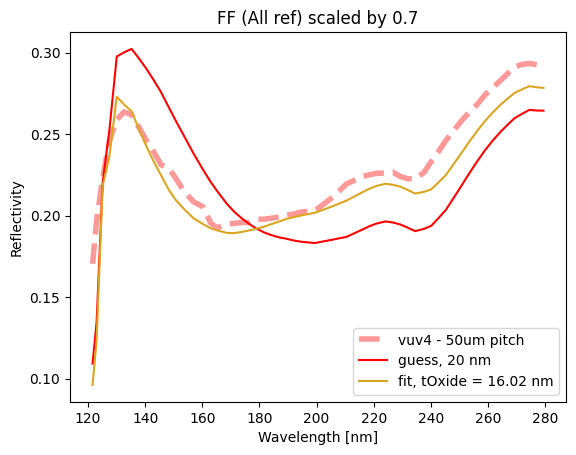

In [29]:
dAngles = {"d1":6.8, "d2":17, "d3":37.2}
FF1 = 0.6*0.7
# FF2 = 0.7*0.7

# dhFoggy = OpticsData(oxideDataPath=proPath+"/opticsData/GoodMerged/silicon_dioxide-merged-foggy.txt")

# add gaussian smoothing

# vertical scaling

# repeat with lmfit

def Ref_wrapped(wlen, toxide):
    
    photon = PhotonInfo(wlen, theta_1=dAngles["d1"], dataHelper=None)
    
    return FF1*photon.Wave_TotalReflection(toxide)

# def Ref_wrapped2(wlen, toxide):
    
#     photon = PhotonInfo(wlen, theta_1=dAngles["d1"], dataHelper=None)
    
#     return FF2*photon.Wave_TotalReflection(toxide)

plt.plot(x1, r1, linewidth = 4, linestyle = "--", alpha = 0.4, color = ms.GetNextColor(), label="vuv4 - 50um pitch")
plt.plot(x1, Ref_wrapped(x1, 20.5), color = ms.GetNextColor(1), label="guess, 20 nm")

# plt.plot(x1, Ref_wrapped(x1, 80), color = ms.GetNextColor(), label="guess, 80 nm")

# plt.plot(x1, Ref_wrapped(x1, 5), color = ms.GetNextColor(), label="guess, 5 nm")

# plt.plot(x2, r2, linewidth = 4, linestyle = "--", color = ms.GetNextColor(), alpha = 0.4, label="vuv4 - 75um pitch")
# plt.plot(x2, Ref_wrapped2(x2, 20.5), color = ms.GetNextColor(1), label="guess, 16.5 nm")


cfit_opts = {"maxfev": 10000, "xtol": 1e-6, "ftol": 1e-6, "absolute_sigma":True}
popt, pcov = curve_fit(Ref_wrapped, x1, r1, p0=[30])
print("fit results")
print(popt)
print(pcov)

plt.xlabel("Wavelength [nm]")
plt.ylabel("Reflectivity")

plt.plot(x1, Ref_wrapped(x1, *popt), label=f"fit, tOxide = {popt[0]:.2f} nm")
# plt.plot(x1, Ref_wrapped(x1, *popt), label=f"fit, tOxide = {popt[0]:.2f} nm")

# smoothed_r1 = gaussian_filter1d(r1, sigma=2)  # Apply Gaussian smoothing
# plt.plot(x1, smoothed_r1, label="Smoothed r1")

plt.title("FF (All ref) scaled by 0.7")
plt.legend()

plt.legend()